# Week 2 homework

Data: 2024 American Time Use Survey, US Bureau of Labor Statistics.
Each row contains an estimated average or difference in daily working hours,
with confidence limits. Variable definitions are in `data/README.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("data/working_time.csv")
data.head()

,day_type,measure,series,estimate_hours,ci_low_hours,ci_high_hours
0,Weekdays,Job-related work,Men,7.857500,7.558580,8.156420
1,Weekdays,Household and care work,Men,1.838531,1.623811,2.053251
2,Weekdays,Combined work,Men,9.696031,9.368479,10.023582
3,Weekdays,Job-related work,Women,6.741170,6.357812,7.124529
4,Weekdays,Household and care work,Women,2.635240,2.440795,2.829685


In [2]:
diff = data[data["series"] == "Women minus men"]
diff

,day_type,measure,series,estimate_hours,ci_low_hours,ci_high_hours
6,Weekdays,Job-related work,Women minus men,-1.116330,-1.591639,-0.641020
7,Weekdays,Household and care work,Women minus men,0.796709,0.523734,1.069684
8,Weekdays,Combined work,Women minus men,-0.319621,-0.787649,0.148408
15,Weekends and holidays,Job-related work,Women minus men,-0.308908,-0.747153,0.129337
16,Weekends and holidays,Household and care work,Women minus men,0.783101,0.401563,1.164640
17,Weekends and holidays,Combined work,Women minus men,0.474194,0.028671,0.919716


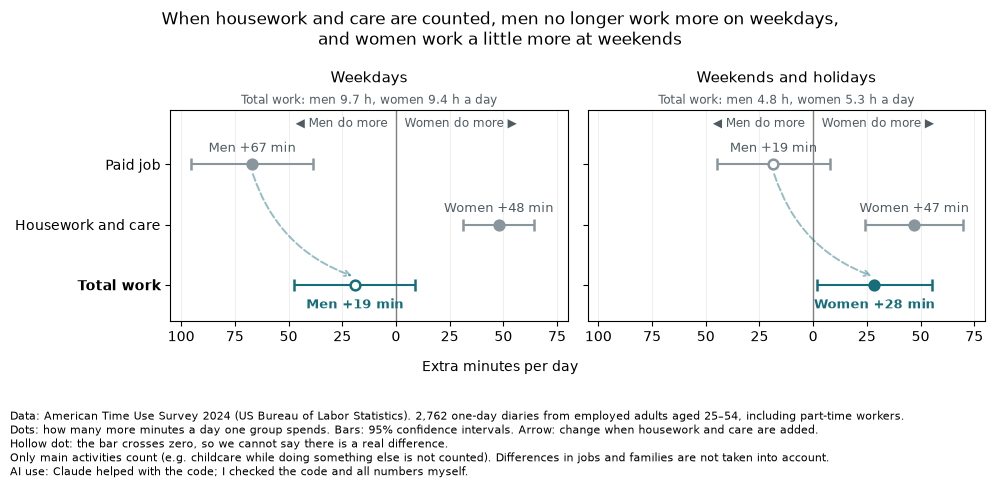

In [3]:
measure_order = ["Job-related work", "Household and care work", "Combined work"]
day_order = ["Weekdays", "Weekends and holidays"]
positions = range(len(measure_order))
# Highlight the combined measure, which answers the question; the parts give context.
main_colour, context_colour = "#176D79", "#8A969E"
label_grey = "#4F5B63"  # darker grey for text, for readability

# Convert hours to minutes so the gaps are easier to picture.
gaps = diff.copy()
for col in ["estimate_hours", "ci_low_hours", "ci_high_hours"]:
    gaps[col.replace("hours", "min")] = gaps[col] * 60

# Average combined working time by sex, to show the scale of the gaps.
levels = data[data["measure"].eq("Combined work") & data["series"].isin(["Men", "Women"])]
levels = levels.pivot(index="day_type", columns="series", values="estimate_hours")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, day in zip(axes, day_order):
    d = gaps[gaps["day_type"].eq(day)].set_index("measure").loc[measure_order]
    for pos, (measure, row) in zip(positions, d.iterrows()):
        colour = main_colour if measure == "Combined work" else context_colour
        # errorbar needs distances from each estimate, not the interval endpoints (as in Lecture 2).
        errors = [[row["estimate_min"] - row["ci_low_min"]],
                  [row["ci_high_min"] - row["estimate_min"]]]
        # Hollow dot when the interval crosses zero: no clear difference.
        unclear = row["ci_low_min"] < 0 < row["ci_high_min"]
        ax.errorbar(row["estimate_min"], pos, xerr=errors, fmt="o",
                    capsize=4, color=colour, markersize=7, zorder=3,
                    markerfacecolor="white" if unclear else colour, markeredgewidth=1.8)
        # Name the group that does more, so readers need not decode the sign.
        who = "Women" if row["estimate_min"] > 0 else "Men"
        ax.annotate(f"{who} +{abs(row['estimate_min']):.0f} min", (row["estimate_min"], pos),
                    xytext=(0, -17 if colour == main_colour else 9), textcoords="offset points", ha="center",
                    fontsize=9, color=main_colour if colour == main_colour else label_grey, fontweight="bold" if colour == main_colour else "normal")
    # Arrow from job-only gap to combined gap: the shift from counting household and care work.
    ax.annotate("", xy=(d.loc["Combined work", "estimate_min"], 2 - 0.13),
                xytext=(d.loc["Job-related work", "estimate_min"], 0 + 0.12),
                arrowprops=dict(arrowstyle="->", color=main_colour, alpha=0.45,
                                linewidth=1.4, linestyle="--", connectionstyle="arc3,rad=0.25"))
    # Zero means women and men spend the same time.
    ax.axvline(0, color="grey", linewidth=1)
    # Label each side of zero inside the panel.
    ax.text(-4, -0.68, "◀ Men do more", ha="right", va="center", fontsize=8.5, color=label_grey)
    ax.text(4, -0.68, "Women do more ▶", ha="left", va="center", fontsize=8.5, color=label_grey)
    ax.set_title(day, fontsize=11, pad=20)
    ax.text(0.5, 1.03, f"Total work: men {levels.loc[day, 'Men']:.1f} h, women {levels.loc[day, 'Women']:.1f} h a day",
            transform=ax.transAxes, ha="center", fontsize=8.5, color=label_grey)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
# Reversed y-limits put the first measure at the top and leave room for the labels.
axes[0].set(yticks=positions, yticklabels=["Paid job", "Housework and care", "Total work"], ylim=(2.6, -0.9), xlim=(-105, 80))
axes[0].get_yticklabels()[2].set_fontweight("bold")
# Show distances from zero without minus signs; the side shows who does more.
axes[0].xaxis.set_major_formatter(lambda x, pos: f"{abs(x):.0f}")
fig.supxlabel("Extra minutes per day", fontsize=10, y=0.22)

fig.suptitle("When housework and care are counted, men no longer work more on weekdays,\n"
             "and women work a little more at weekends", fontsize=12)
fig.text(0.01, 0.01,
         "Data: American Time Use Survey 2024 (US Bureau of Labor Statistics). 2,762 one-day diaries from employed adults aged 25–54, including part-time workers.\n"
         "Dots: how many more minutes a day one group spends. Bars: 95% confidence intervals. Arrow: change when housework and care are added.\n"
         "Hollow dot: the bar crosses zero, so we cannot say there is a real difference.\n"
         "Only main activities count (e.g. childcare while doing something else is not counted). Differences in jobs and families are not taken into account.\n"
         "AI use: Claude helped with the code; I checked the code and all numbers myself.",
         fontsize=8)
fig.tight_layout(rect=(0, 0.19, 1, 1))
fig.savefig("figures/hw02_working_time_gap.png", dpi=150, bbox_inches="tight")
plt.show()